In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '2_train_clean2.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_val_fe.parquet')
test = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_test_fe.parquet')

train_full = pd.concat(
    [train, val]
)

print(train.shape, val.shape, train_full.shape, test.shape)

(616299, 35) (133325, 35) (749624, 35) (186263, 33)


In [2]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

# 시계열 컬럼군
time_cols = [
    'wl_t',          # 수위데이터 대표
    'sfc_rain_1h',   # 육상 누적강수데이터 대표
    'imerg_rain_1h', # 위성 누적강수데이터 대표
    'radar_reflectivity_mean', # 레이더반사도 대표
    'radar_reflectivity_p95', # 레이더반사도 대표
]

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)}, 
    환경변수: {len(env_cols)}, 
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)}, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9, 
    환경변수: 7, 
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [3]:
# ============================================================
# 2. env_cols 분석 필요여부 확인하기
# ============================================================
# train, val셋과 train셋의 station_id가 동일하다면 불필

print(
    'train셋 \'station_id\' 개수: ',
    len(set(train['station_id']))
)

print(
    'train, val셋 \'station_id\' 교집합 개수: ',
    len(
        set(train['station_id']) & set(val['station_id'])
    )
)

print(
    'train, val, test셋 \'station_id\' 교집합 개수: ',
    len(
        set(train['station_id']) & set(val['station_id']) & set(test['station_id'])
    )
)

print(
    'test셋에만 있는 \'station_id\' 개수: ',
    len(set(test['station_id']) - set(train['station_id']) - set(val['station_id']))
)

# test셋도 1관측소당 유역환경변수가 중복없이 1데이터 인지 확인
test_env_gb = test.groupby('station_id')[env_cols].nunique().max()
print(test_env_gb)
# env_cols는 분석 제외

train셋 'station_id' 개수:  465
train, val셋 'station_id' 교집합 개수:  465
train, val, test셋 'station_id' 교집합 개수:  465
test셋에만 있는 'station_id' 개수:  0
cat_area          1
wsarea            1
mean_elevation    1
mean_slope        1
urban_ratio       1
forest_ratio      1
stream_order      1
dtype: int64


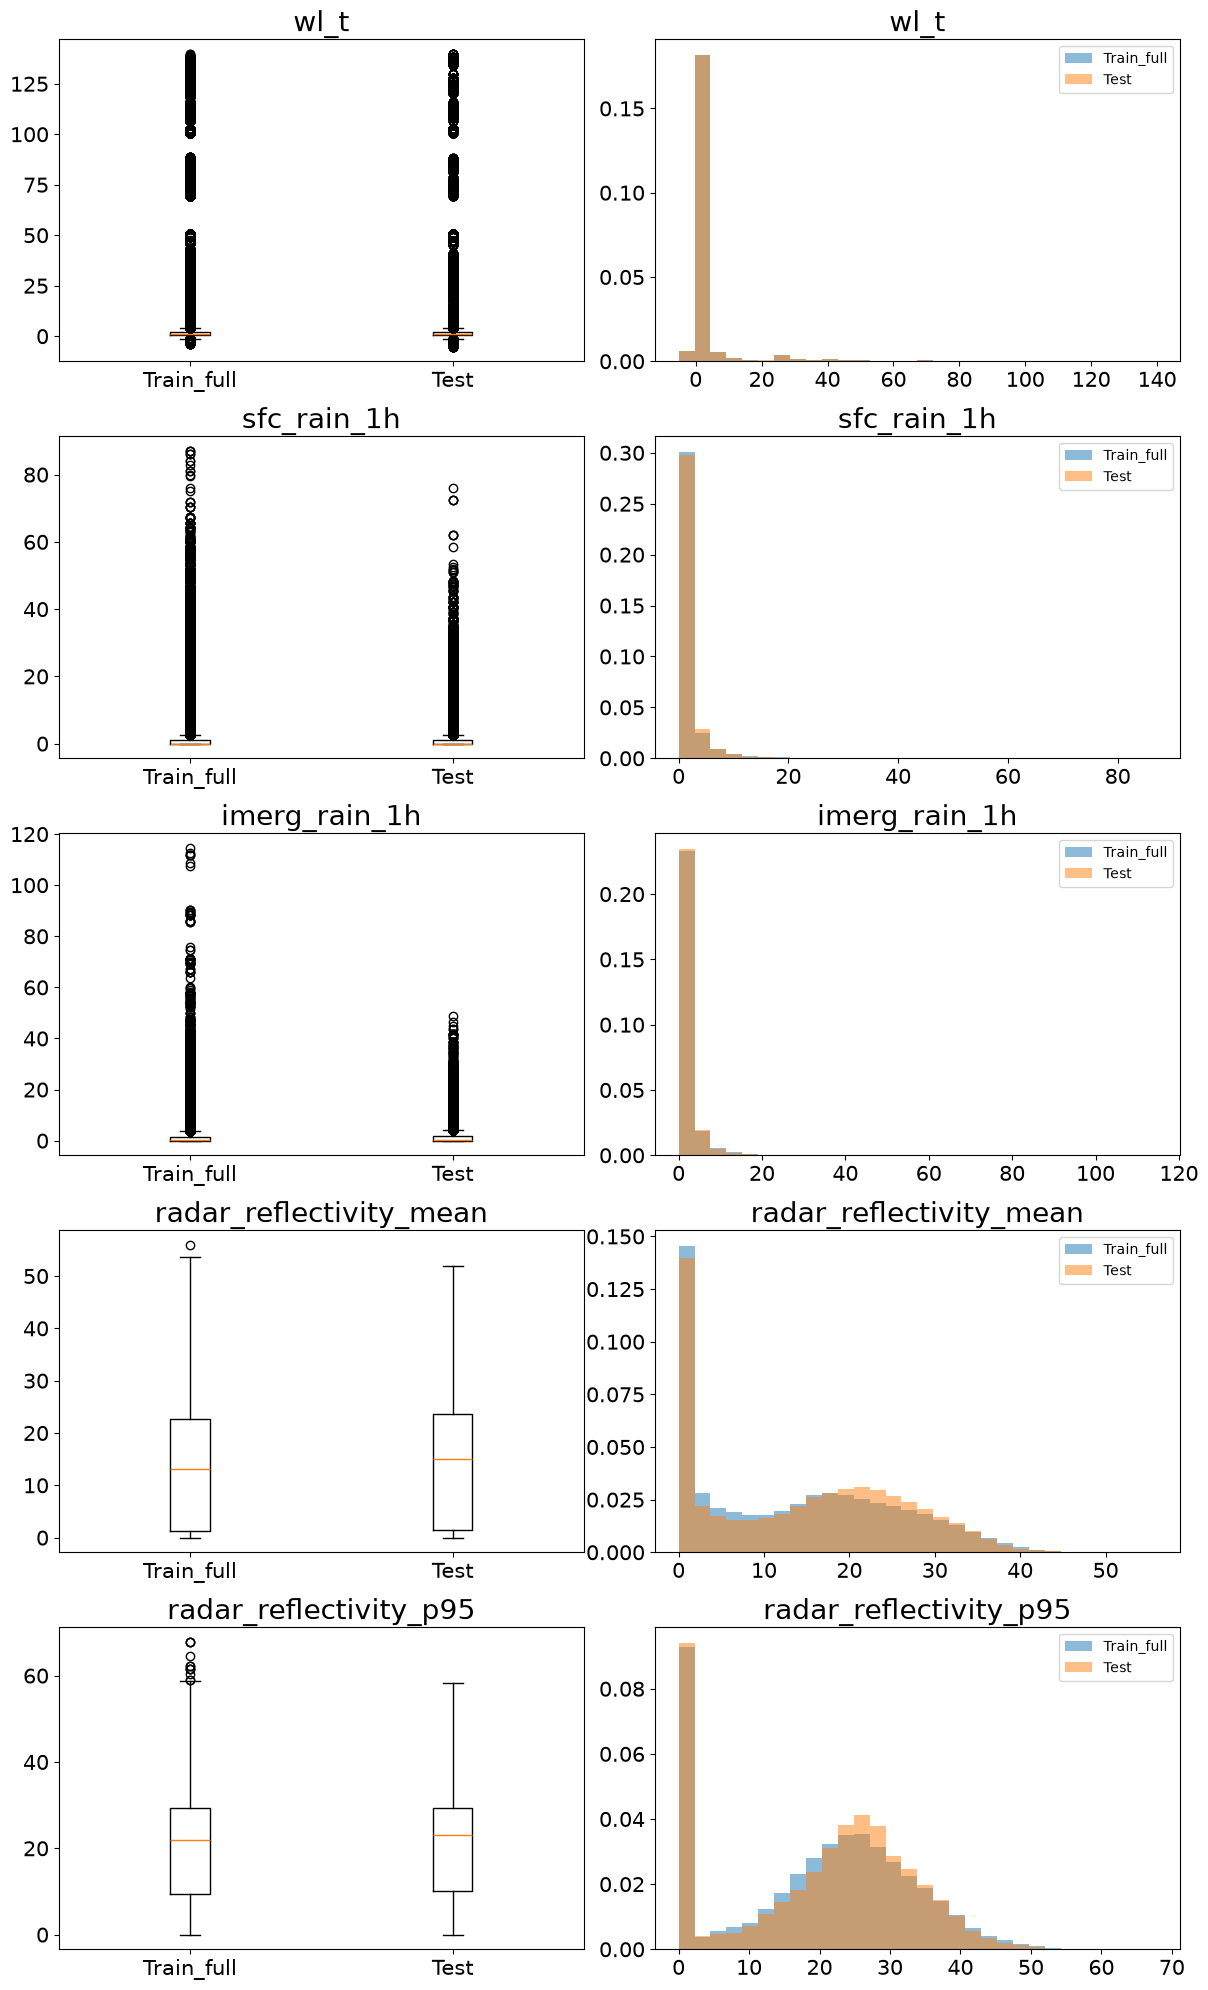

In [ ]:
# ======================================================================
# 3-1. (시계열) train, val 데이터 박스플롯, 히스토그램 비교하기: 분포 비교용
# ======================================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(time_cols),
    2,
    figsize = (12, 4 * len(time_cols)))

if len(time_cols) == 1:
    axes = [axes]

for i, col in enumerate(time_cols):
    
    tr_f = train_full[col].dropna()
    te = test[col].dropna()

    axes[i][0].boxplot([tr_f, te], tick_labels=['Train_full', 'Test'])
    axes[i][0].set_title(col, fontsize=20)
    axes[i][0].tick_params(labelsize=15)

    axes[i][1].hist(
        tr_f,
        range=(min(tr_f.min(), te.min()), max(tr_f.max(), te.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Train_full'
    )
    axes[i][1].hist(
        te,
        range=(min(tr_f.min(), te.min()), max(tr_f.max(), te.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Test'
    )
    axes[i][1].set_title(col, fontsize=20)
    axes[i][1].tick_params(labelsize=15)
    axes[i][1].legend

plt.tight_layout()
plt.show()

In [4]:
# ======================================================================
# 3-2. (시계열) 기초통계량 비교: 시계열데이터 전부 다 비교
# ======================================================================

q = [0, 0.01, 0.05, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]

for col in [col for col in num_cols_fe if col not in env_cols]:
    print(col)
    print(pd.DataFrame(
        {
            'Train' : train[col].quantile(q).round(1),
            'Validation' : val[col].quantile(q).round(1),
            'Val/Train' : (val[col].quantile(q)/train[col].quantile(q)).round(1),
            'Train_full' : train_full[col].quantile(q).round(1),
            'Test' : test[col].quantile(q).round(1),
            'Test/Train_f': (test[col].quantile(q)/train_full[col].quantile(q)).round(1),
            'Test/Val' : (test[col].quantile(q)/val[col].quantile(q)).round(1)
        }
    )
    .to_csv(sep='\t'))
    print()


wl_t
	Train	Validation	Val/Train	Train_full	Test	Test/Train_f	Test/Val
0.0	-3.8	-3.8	1.0	-3.8	-5.2	1.3	1.3
0.01	-1.0	-1.1	1.1	-1.0	-1.0	1.0	1.0
0.05	-0.1	-0.1	1.1	-0.1	-0.1	1.2	1.1
0.5	1.1	1.1	1.0	1.1	1.2	1.0	1.0
0.75	2.0	1.9	1.0	2.0	2.0	1.0	1.1
0.9	4.0	3.7	0.9	4.0	4.0	1.0	1.1
0.95	25.0	25.0	1.0	25.0	25.0	1.0	1.0
0.99	78.8	79.3	1.0	78.8	81.4	1.0	1.0
1.0	139.6	136.8	1.0	139.6	139.7	1.0	1.0


wl_t_minus_1h
	Train	Validation	Val/Train	Train_full	Test	Test/Train_f	Test/Val
0.0	-3.9	-3.7	0.9	-3.9	-5.2	1.3	1.4
0.01	-1.0	-1.1	1.1	-1.0	-1.0	1.0	1.0
0.05	-0.1	-0.1	1.0	-0.1	-0.1	1.1	1.1
0.5	1.1	1.1	1.0	1.1	1.1	1.0	1.0
0.75	2.0	1.9	1.0	2.0	2.0	1.0	1.1
0.9	4.0	3.7	0.9	3.9	4.0	1.0	1.1
0.95	25.0	25.0	1.0	25.0	25.0	1.0	1.0
0.99	78.8	79.3	1.0	78.8	81.3	1.0	1.0
1.0	139.7	136.8	1.0	139.7	139.7	1.0	1.0


wl_t_minus_3h
	Train	Validation	Val/Train	Train_full	Test	Test/Train_f	Test/Val
0.0	-3.9	-3.7	0.9	-3.9	-5.2	1.3	1.4
0.01	-1.0	-1.1	1.1	-1.0	-1.0	1.0	1.0
0.05	-0.1	-0.1	1.1	-0.1	-0.1	1.2	1.1
0.5	1.1	1.1	1

In [14]:
# ======================================================================
# (추가분석) 수위변수군 전체의 0분위수 중 test셋만 -5.2로 이상치 분석
# ======================================================================

cond_test_min_wl = test['wl_t'] < -5
print(f"6h이내 수위변동이 -5보다 작은 데이터 개수: {cond_test_min_wl.sum()}")
test.loc[cond_test_min_wl, ['timestamp', 'station_id'] + time_cols]

# 수위기준으로 줄을 세워 기준값에서 벗어나는지 확인
# print(
#     test.loc[
#         test['station_id'] == 'ST0436',
#         ['timestamp', 'station_id'] + time_cols
#     ]
#     .sort_values(['wl_t', 'timestamp'])
#     .to_csv(sep='\t')
# )


# 이상치 전후 시계열 탐색
display(
    test.loc[
        (test['station_id'] == 'ST0436') &
        (
            (test['timestamp'].between('2102-12-26 00:00:00', '2102-12-28 12:00:00')) |
            (test['timestamp'].between('2103-11-02 00:00:00', '2103-11-03 00:00:00'))
        ),
    ['timestamp', 'station_id'] + wl_cols
].sort_values('timestamp')
)

6h이내 수위변동이 -5보다 작은 데이터 개수: 13


,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,
TE_000166886,2102-12-27 00:00:00,ST0436,-5.18,-5.18,-5.19,-5.19,-5.19,-5.19
TE_000118763,2102-12-27 01:00:00,ST0436,-5.17,-5.18,-5.19,-5.19,-5.19,-5.18
TE_000050700,2102-12-27 02:00:00,ST0436,-5.17,-5.17,-5.18,-5.19,-5.20,-5.17
TE_000171285,2102-12-27 03:00:00,ST0436,-5.16,-5.17,-5.18,-5.19,-5.19,-5.17
TE_000044147,2102-12-27 04:00:00,ST0436,-5.16,-5.16,-5.17,-5.19,-5.19,-5.17
TE_000107495,2102-12-27 05:00:00,ST0436,-5.15,-5.16,-5.17,-5.18,-5.19,-5.17
TE_000151241,2102-12-27 06:00:00,ST0436,-5.15,-5.15,-5.16,-5.18,-5.19,-5.17
TE_000182268,2102-12-27 07:00:00,ST0436,-5.14,-5.15,-5.16,-5.17,-5.19,-5.17
TE_000162483,2102-12-27 08:00:00,ST0436,-5.13,-5.14,-5.15,-5.17,-5.19,-5.18


In [26]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================

# 12h 수위차분변수는 train만 0, 1분위수가 혼자 낮고 높음, 확인필요
cond = (train['wl_diff_12h'] < -4) | (train['wl_diff_12h'] > 7)

print(f'해당 행 수: {cond.sum()}')

# train.loc[cond, [
#     'timestamp', 'station_id',
#     'wl_diff_12h' 
# ] + wl_cols
# ].sort_values(['wl_diff_12h', 'timestamp'])

print(
    train.loc[
        (train['station_id'] == 'ST0089') &
        (train['timestamp'].between(
            '2101-12-31 00:00:00',
            '2102-01-02 00:00:00'
        )),
        ['timestamp', 'station_id', 'wl_diff_12h'] + wl_cols
].sort_values(['wl_diff_12h', 'timestamp'])
.to_csv(sep='\t'))

# train ST0089 3개 이상치 확정
# 이상치 제거 조건 설정
cond_train_out1 = [
    'TR_000547855',
    'TR_000457689',
    'TR_000318564'
]

해당 행 수: 44
row_id	timestamp	station_id	wl_diff_12h	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h
TR_000547855	2102-01-01 07:00:00	ST0089	-6.35	0.03	0.01	0.01	6.38	6.38	6.38
TR_000457689	2102-01-01 10:00:00	ST0089	-6.27	0.11	0.1	0.03	0.01	6.38	6.38
TR_000318564	2102-01-01 21:00:00	ST0089	0.37	0.47	0.42	0.18	0.16	0.1	6.38



In [34]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================
# 24h 수위차분변수, train, 0분위수

# 조건으로 이상치 탐지
cond = train['wl_diff_24h'] < -6

print(f'Train: {cond.sum()}행')
print(
    train.loc[
        cond,
        ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
    ].sort_values(['wl_diff_24h', 'timestamp'])
    .to_csv(sep='\t')
)

# 전후 시계열 확인
print(
    train.loc[
        (train['station_id'] == 'ST0158') &
        (train['timestamp'].between(
            '2102-05-10 00:00:00',
            '2102-05-12 12:00:00'
        )),
        ['timestamp', 'station_id'] + wl_cols + wl_diff_cols
    ].sort_values('timestamp')
    .to_csv(sep='\t')
)

# 이상치 확정 리스트 (3개)
cond_train_out2 = [
    'TR_000193482',
    'TR_000057205',
    'TR_000154692'
]

Train: 21행
row_id	timestamp	station_id	wl_diff_24h	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h
TR_000076779	2103-06-10 03:00:00	ST0412	-8.85	2.49	2.73	3.29	4.19	6.11	11.34
TR_000260409	2103-06-10 04:00:00	ST0412	-8.75	2.29	2.49	3.01	3.89	5.78	11.04
TR_000194526	2103-06-10 02:00:00	ST0412	-8.639999999999999	2.73	3.01	3.59	4.49	6.47	11.37
TR_000001659	2103-06-10 05:00:00	ST0412	-8.489999999999998	2.13	2.29	2.73	3.59	5.47	10.62
TR_000628761	2103-06-10 06:00:00	ST0412	-8.18	2.0	2.13	2.49	3.29	5.13	10.18
TR_000514035	2103-06-10 01:00:00	ST0412	-7.91	3.01	3.29	3.89	4.8	6.89	10.92
TR_000222952	2103-06-10 07:00:00	ST0412	-7.91	1.9	2.0	2.29	3.01	4.8	9.81
TR_000255390	2103-06-10 08:00:00	ST0412	-7.58	1.81	1.9	2.13	2.73	4.49	9.39
TR_000193482	2102-05-11 00:00:00	ST0158	-7.39	0.0	0.0	0.0	0.0	0.0	7.39
TR_000057205	2102-05-11 01:00:00	ST0158	-7.39	0.0	0.0	0.0	0.0	0.0	7.39
TR_000154692	2102-05-11 02:00:00	ST0158	-7.39	0.0	0.0	0.0	0.0	0.0	7.39
TR_000709428	2103-06-10 0

In [35]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================
# 24h 수위차분변수, val, 0분위수
# 조건으로 이상치 탐지
cond = val['wl_diff_24h'] < -6

print(f'Validation: {cond.sum()}행')
print(
    val.loc[
        cond,
        ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
    ].sort_values(['wl_diff_24h', 'timestamp'])
    .to_csv(sep='\t')
)

# 전후 시계열 확인
print(
    val.loc[
        cond,
        ['timestamp', 'station_id'] + wl_cols + wl_diff_cols
    ].sort_values(['station_id', 'timestamp'])
    .to_csv(sep='\t')
)

# 이상치 확정 리스트 (9개)
cond_val_out1 = [
    'TR_000468355',
    'TR_000450715',
    'TR_000267036',
    'TR_000185855',
    'TR_000385460',
    'TR_000665570',
    'TR_000480061',
    'TR_000476408',
    'TR_000715299'
]

Validation: 19행
row_id	timestamp	station_id	wl_diff_24h	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h
TR_000468355	2103-12-02 00:00:00	ST0448	-9.59	0.0	0.0	0.0	0.0	0.0	9.59
TR_000450715	2103-12-02 01:00:00	ST0448	-9.59	0.0	0.0	0.0	0.0	0.0	9.59
TR_000267036	2103-12-02 02:00:00	ST0448	-9.59	0.0	0.0	0.0	0.0	0.0	9.59
TR_000185855	2103-12-02 04:00:00	ST0448	-9.59	0.0	0.0	0.0	0.0	0.0	9.59
TR_000385460	2103-12-02 05:00:00	ST0448	-9.59	0.0	0.0	0.0	0.0	0.0	9.59
TR_000665570	2103-12-02 06:00:00	ST0448	-9.59	0.0	0.0	0.0	0.0	0.0	9.59
TR_000480061	2103-12-02 07:00:00	ST0448	-9.59	0.0	0.0	0.0	0.0	0.0	9.59
TR_000476408	2103-12-02 03:00:00	ST0448	-9.57	0.0	0.0	0.0	0.0	0.0	9.57
TR_000715299	2103-12-02 00:00:00	ST0007	-8.75	0.0	0.0	0.0	0.0	0.0	8.75
TR_000111676	2103-12-02 05:00:00	ST0445	-7.58	3.4	3.43	3.47	3.54	4.34	10.98
TR_000548059	2103-12-02 06:00:00	ST0445	-7.4799999999999995	3.38	3.4	3.44	3.48	4.26	10.86
TR_000320551	2103-12-02 03:00:00	ST0445	-7.390000000000001	3.4

In [33]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================
# 24h 수위차분변수, test, 0분위수
# 조건으로 이상치 탐지
cond = test['wl_diff_24h'] < -6

print(f'Test: {cond.sum()}행')
print(
    test.loc[
        cond,
        ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
    ].sort_values(['wl_diff_24h', 'timestamp'])
    .to_csv(sep='\t')
)

# 전후 시계열 확인
print(
    test.loc[
        (test['station_id'] == 'ST0158') &
        (test['timestamp'].between(
            '2102-12-26 07:00:00',
            '2102-12-28 07:00:00'
        )),
        ['timestamp', 'station_id'] + wl_cols + wl_diff_cols
    ].sort_values('timestamp')
    .to_csv(sep='\t')
)

# 이상치 의심 리스트 (제거하지 않음)
cond_test_out1 = [
    'TE_000112883'
]

Test: 1행
row_id	timestamp	station_id	wl_diff_24h	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h
TE_000112883	2102-12-27 07:00:00	ST0158	-6.3100000000000005	0.22	0.22	0.22	0.22	0.23	6.53

row_id	timestamp	station_id	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h	wl_t	wl_diff_1h	wl_diff_3h	wl_diff_6h	wl_diff_12h	wl_diff_24h
TE_000112883	2102-12-27 07:00:00	ST0158	0.22	0.22	0.22	0.22	0.23	6.53	0.22	0.0	0.0	0.0	-0.010000000000000009	-6.3100000000000005
TE_000054685	2102-12-27 08:00:00	ST0158	0.22	0.22	0.22	0.22	0.23	0.21	0.22	0.0	0.0	0.0	-0.010000000000000009	0.010000000000000009
TE_000063023	2102-12-27 09:00:00	ST0158	0.2	0.22	0.22	0.22	0.23	0.2	0.2	-0.01999999999999999	-0.01999999999999999	-0.01999999999999999	-0.03	0.0
TE_000131077	2102-12-27 10:00:00	ST0158	0.19	0.2	0.22	0.22	0.23	0.2	0.19	-0.010000000000000009	-0.03	-0.03	-0.04000000000000001	-0.010000000000000009



In [39]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================
# 24h 수위차분변수, train 1분위수 11.6으로 너무 높아 확인 필요: 이상치 판단근거 없음, 보류

# 조건으로 이상치 탐지
cond = train['wl_diff_24h'] > 10

print(f'Train: {cond.sum()}행')
display(
    train.loc[
        cond,
        ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
    ].sort_values(['wl_diff_24h', 'timestamp'])
)

Train: 7행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000205388,2103-06-09 00:00:00,ST0412,10.13,9.94,8.30,5.24,2.28,0.19,-0.19
TR_000265444,2103-06-09 06:00:00,ST0412,10.34,10.18,10.62,11.34,9.94,2.28,-0.16
TR_000346396,2103-06-09 05:00:00,ST0412,10.80,10.62,11.04,11.37,8.30,2.01,-0.18
TR_000457777,2103-06-09 01:00:00,ST0412,11.11,10.92,9.94,6.65,2.62,0.35,-0.19
TR_000248117,2103-06-09 04:00:00,ST0412,11.22,11.04,11.34,10.92,6.65,1.65,-0.18
TR_000649987,2103-06-09 03:00:00,ST0412,11.53,11.34,11.37,9.94,5.24,1.26,-0.19
TR_000216027,2103-06-09 02:00:00,ST0412,11.56,11.37,10.92,8.30,3.77,0.72,-0.19


In [46]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================
# 24h 수위차분변수, val 1분위수 6.1로 test보다 높아 확인 필요: 이상치 판단근거 없음, 보류

# 조건으로 이상치 탐지
cond = test['wl_diff_24h'] > 4.5

print(f'Test: {cond.sum()}행')
display(
    test.loc[
        cond,
        ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
    ].sort_values(['wl_diff_24h', 'timestamp'])
)

Test: 7행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TE_000160189,2102-11-08 23:00:00,ST0101,4.50,9.22,9.15,8.75,7.94,6.34,4.72
TE_000099878,2101-10-04 07:00:00,ST0221,4.51,7.80,7.75,7.37,6.80,4.93,3.29
TE_000140040,2102-11-09 02:00:00,ST0010,4.52,6.47,6.38,6.06,4.76,3.26,1.95
TE_000058442,2102-11-09 03:00:00,ST0010,4.55,6.51,6.47,6.27,5.21,3.49,1.96
TE_000011305,2102-11-09 04:00:00,ST0010,4.62,6.58,6.51,6.38,5.66,3.65,1.96
TE_000163685,2102-11-09 05:00:00,ST0010,4.65,6.62,6.58,6.47,6.06,3.83,1.97
TE_000175164,2102-10-18 04:00:00,ST0067,4.67,5.53,5.29,3.94,1.68,1.87,0.86


In [ ]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================
# 24h 수위차분변수, test 1분위수 제일 낮으나 확인차

# 조건으로 이상치 탐지
cond = val['wl_diff_24h'] > 4

print(f'Train: {cond.sum()}행')
display(
    val.loc[
        cond,
        ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
    ].sort_values(['wl_diff_24h', 'timestamp'])
)

In [ ]:
# ======================================================================
# (추가분석) 12h, 24h 수위차분변수군 0분위수와 1분위수에서 이상치 의심, 추가분석
# ======================================================================
# 24h 수위차분변수는 1분위수가 train셋이 11.6으로 월등함
# 일단 세가지 차이가 명확하므로 다 탐색

for name, df in [('Train', train), ('Validation', val), ('Test', test)]:

    cond = df['wl_diff_24h'] > 5

    print(f'\n{name}: {cond.sum()}행')

    display(
        df.loc[
            cond,
            ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
        ].sort_values(['wl_diff_24h', 'timestamp'])
    )